# ResNet-56 (CIFAR-10)

In [14]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Liczę na:", device)

Liczę na: cuda


##### 1. Dataset

In [15]:
raw = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)

indices = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
train_idx, val_idx = indices[:45000], indices[45000:]

# "per-pixel mean subtracted": średni obraz 3×32×32 liczony tylko na części treningowej
MEAN_IMAGE = torch.tensor(raw.data[train_idx.numpy()].mean(axis=0) / 255.0, dtype=torch.float32).permute(2, 0, 1)

print("mean image:", tuple(MEAN_IMAGE.shape))
print("średnia per kanał:", [round(m, 4) for m in MEAN_IMAGE.mean(dim=(1, 2)).tolist()])

Files already downloaded and verified
mean image: (3, 32, 32)
średnia per kanał: [0.4917, 0.4823, 0.4467]


In [16]:
class SubtractMean:
    def __init__(self, mean_image):
        self.mean_image = mean_image

    def __call__(self, x):
        return x - self.mean_image


# padding 4 px (zerami, czyli wartością średnią), losowy crop 32×32, losowe odbicie poziome
train_transform = transforms.Compose([
    transforms.ToTensor(),
    SubtractMean(MEAN_IMAGE),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    SubtractMean(MEAN_IMAGE),
])

train_data = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
val_source = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=test_transform)
test_data = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_set = Subset(train_data, train_idx)
val_set = Subset(val_source, val_idx)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

print("train:", len(train_set), "| validation:", len(val_set), "| test:", len(test_data))
print("iteracji na epokę:", len(train_loader))

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
train: 45000 | validation: 5000 | test: 10000
iteracji na epokę: 352


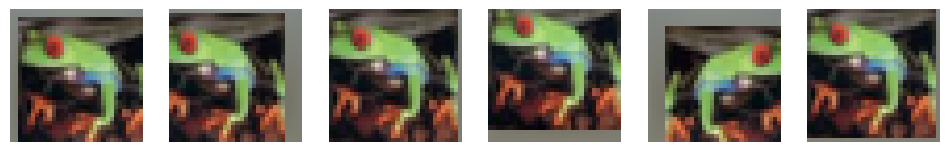

Kształt batcha: (128, 3, 32, 32)


In [17]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax in axes:
    x, label = train_set[0]
    ax.imshow((x + MEAN_IMAGE).permute(1, 2, 0).clamp(0, 1))
    ax.axis("off")
plt.show()

images, labels = next(iter(train_loader))
print("Kształt batcha:", tuple(images.shape))

##### 2. Residual block

In [18]:
class ResidualBlock(nn.Module):
    """y = relu(F(x) + shortcut(x)),  F = BN(conv(relu(BN(conv(x)))))"""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.stride = stride
        self.extra_channels = out_channels - in_channels

    def shortcut(self, x):
        # opcja A: identity, przy zmianie wymiaru subsampling stride 2 + kanały dopełnione zerami (bez parametrów)
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra_channels > 0:
            x = F.pad(x, (0, 0, 0, 0, 0, self.extra_channels))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

In [19]:
x = torch.randn(8, 16, 32, 32)

block = ResidualBlock(16, 16)
print("identity block:    ", tuple(x.shape), "->", tuple(block(x).shape))

down = ResidualBlock(16, 32, stride=2)
s = down.shortcut(x)
print("downsampling block:", tuple(x.shape), "->", tuple(down(x).shape))
print("shortcut = x[:, :, ::2, ::2] + zerowe kanały?",
      torch.equal(s[:, :16], x[:, :, ::2, ::2]) and bool((s[:, 16:] == 0).all()))

# jeśli F(x) = 0, blok staje się identycznością (dla x >= 0, czyli po ReLU)
zero_block = ResidualBlock(16, 16)
nn.init.zeros_(zero_block.bn2.weight)
x_pos = x.relu()
print("F(x) = 0  ->  y == x?", torch.allclose(zero_block(x_pos), x_pos))

identity block:     (8, 16, 32, 32) -> (8, 16, 32, 32)
downsampling block: (8, 16, 32, 32) -> (8, 32, 16, 16)
shortcut = x[:, :, ::2, ::2] + zerowe kanały? True
F(x) = 0  ->  y == x? True


##### 3. Model

In [20]:
class ResNet(nn.Module):
    def __init__(self, depth):
        super().__init__()
        n = (depth - 2) // 6  # 6n+2 warstw, dla 56: n = 9 bloków na etap

        layers = []
        layers += [nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU()]
        layers += [ResidualBlock(16, 16) for _ in range(n)]                                         # 32×32, 16 filtrów
        layers += [ResidualBlock(16, 32, stride=2)] + [ResidualBlock(32, 32) for _ in range(n - 1)]  # 16×16, 32 filtry
        layers += [ResidualBlock(32, 64, stride=2)] + [ResidualBlock(64, 64) for _ in range(n - 1)]  # 8×8, 64 filtry
        layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)]
        self.layers = nn.Sequential(*layers)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

    def forward(self, x):
        return self.layers(x)

In [21]:
model = ResNet(depth=56)
n_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in model.modules())
n_params = sum(p.numel() for p in model.parameters())
out = model(images[:4])
print("warstwy z wagami:", n_layers, "| parametry:", n_params, "(artykuł: 0.85M) | output:", tuple(out.shape))

warstwy z wagami: 56 | parametry: 853018 (artykuł: 0.85M) | output: (4, 10)


##### 4. Training loop

In [22]:
LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = F.cross_entropy(out, y)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)

    return total_loss / n, correct / n


def milestones_for(epochs):
    # jak w artykule: lr / 10 po 50% i 75% treningu (32k i 48k z 64k iteracji)
    return [epochs // 2, epochs * 3 // 4]


def train_model(model, epochs, lr=LR):
    model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones_for(epochs), gamma=0.1)
    history = []

    for epoch in range(1, epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        scheduler.step()

        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"epoch {epoch:2d} | lr {lr_now:.3f} | train: loss {train_loss:.3f}, accuracy {train_acc:.1%} | "
              f"val: loss {val_loss:.3f}, accuracy {val_acc:.1%}")

    return history

##### 5. Training

In [23]:
EPOCHS = 30

torch.manual_seed(42)
model = ResNet(depth=56)
history = train_model(model, epochs=EPOCHS)
torch.save(model.state_dict(), "resnet56.pt")

epoch  1 | lr 0.100 | train: loss 2.253, accuracy 18.8% | val: loss 1.962, accuracy 25.7%
epoch  2 | lr 0.100 | train: loss 1.805, accuracy 32.1% | val: loss 1.816, accuracy 34.9%
epoch  3 | lr 0.100 | train: loss 1.560, accuracy 42.5% | val: loss 1.563, accuracy 46.5%
epoch  4 | lr 0.100 | train: loss 1.288, accuracy 53.5% | val: loss 1.226, accuracy 56.7%
epoch  5 | lr 0.100 | train: loss 1.101, accuracy 60.8% | val: loss 1.048, accuracy 62.7%
epoch  6 | lr 0.100 | train: loss 0.960, accuracy 66.1% | val: loss 0.913, accuracy 67.5%
epoch  7 | lr 0.100 | train: loss 0.857, accuracy 69.8% | val: loss 0.841, accuracy 70.9%
epoch  8 | lr 0.100 | train: loss 0.776, accuracy 73.0% | val: loss 0.804, accuracy 71.9%
epoch  9 | lr 0.100 | train: loss 0.705, accuracy 75.5% | val: loss 0.699, accuracy 76.0%
epoch 10 | lr 0.100 | train: loss 0.649, accuracy 77.5% | val: loss 0.677, accuracy 77.1%
epoch 11 | lr 0.100 | train: loss 0.608, accuracy 78.8% | val: loss 0.775, accuracy 74.5%
epoch 12 |

##### 6. Results

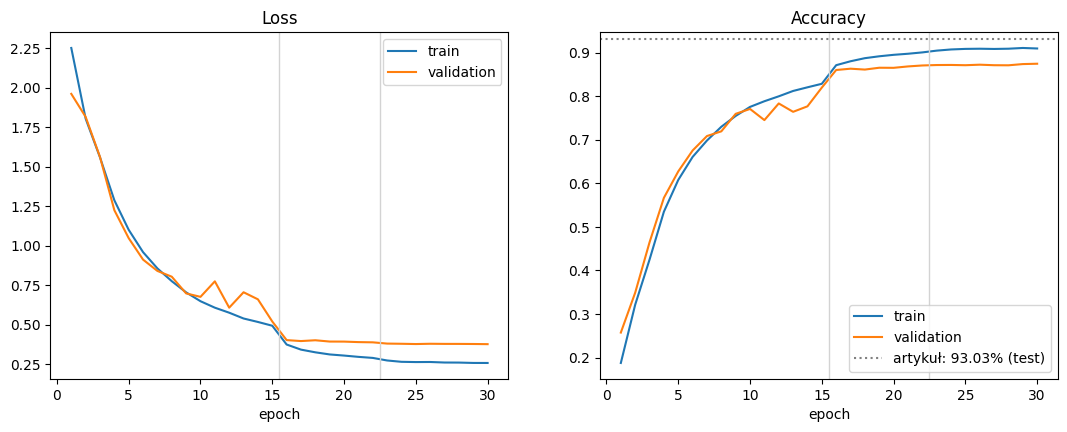

In [24]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs, [h["train_loss"] for h in history], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="validation")
axes[0].set_title("Loss")

axes[1].plot(epochs, [h["train_acc"] for h in history], label="train")
axes[1].plot(epochs, [h["val_acc"] for h in history], label="validation")
axes[1].axhline(1 - 0.0697, color="gray", linestyle=":", label="artykuł: 93.03% (test)")
axes[1].set_title("Accuracy")

for ax in axes:
    for m in milestones_for(EPOCHS):
        ax.axvline(m + 0.5, color="lightgray", linewidth=1)  # zmiana lr
    ax.set_xlabel("epoch")
    ax.legend()

plt.show()

In [25]:
test_loss, test_acc = run_epoch(model, test_loader)
print(f"Test set: loss {test_loss:.3f}, accuracy {test_acc:.1%} | artykuł: 93.03%")

Test set: loss 0.394, accuracy 87.2% | artykuł: 93.03%
